In [1]:
import numpy as np
import matplotlib.pyplot as plt

import os
from statsmodels.stats.weightstats import DescrStatsW

import numpy as np
import scipy.stats as stats

In [ ]:
####################################################################################
#                                 MSM version
####################################################################################

---------------------------------------------:ucp1


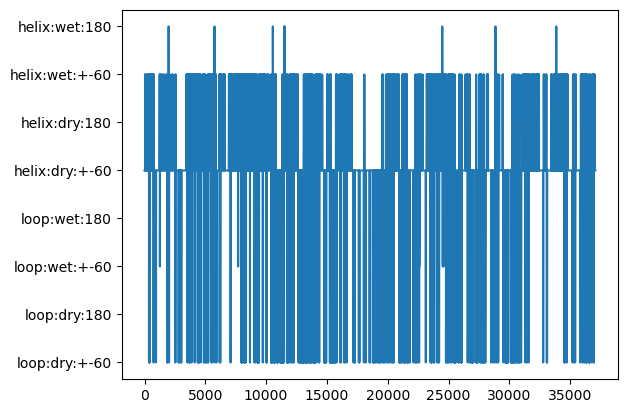

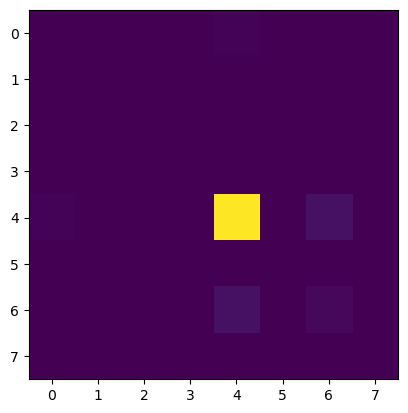

[[32696     2  1481     7]
 [    2     0     0     0]
 [ 1480     0   705     1]
 [    7     0     1     0]]
-------------------------------------------------------------------


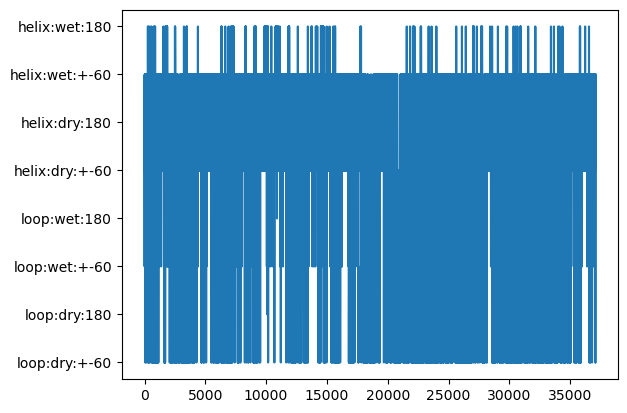

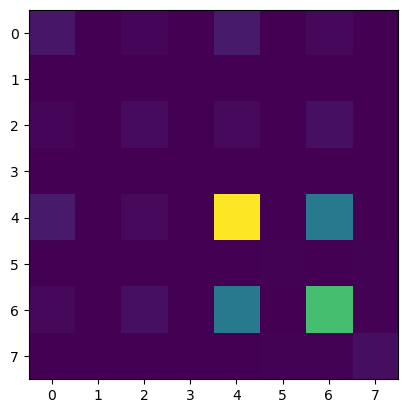

[[12189    20  4932    37]
 [   20    83    14    75]
 [ 4926    11  8578    64]
 [   42    77    59   457]]
-------------------------------------------------------------------


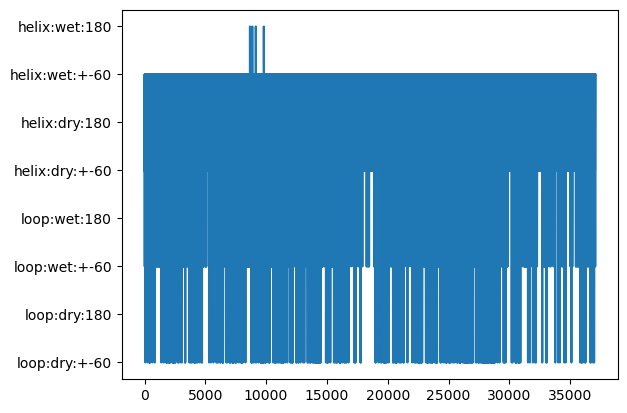

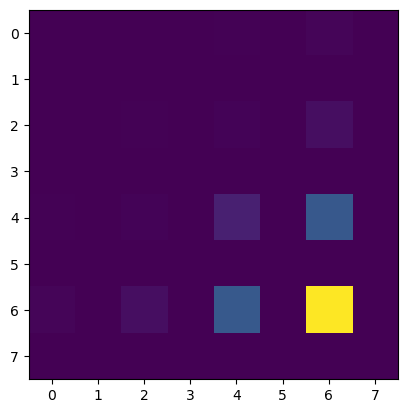

[[ 1814     0  5765     0]
 [    0     0     1     0]
 [ 5780     0 20806     4]
 [    0     1     1     0]]
-------------------------------------------------------------------


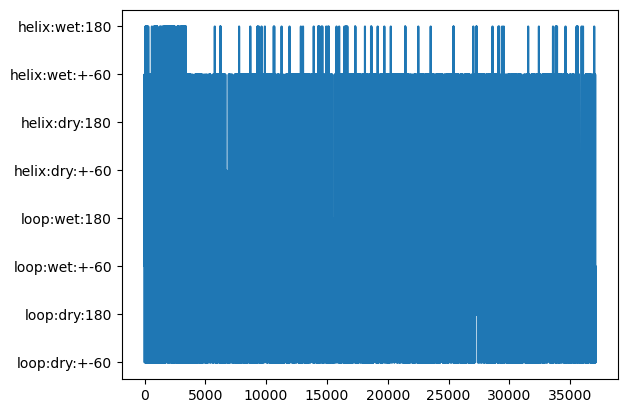

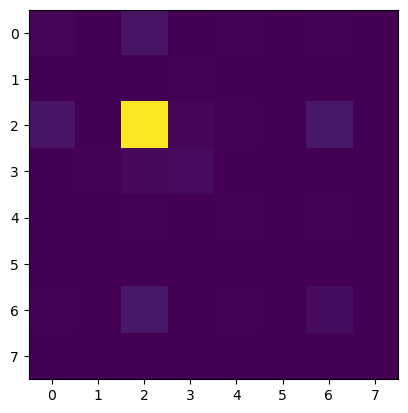

[[174   5 143   4]
 [  2  11   6  19]
 [143   5 840  36]
 [ 11  12  44  64]]
-------------------------------------------------------------------


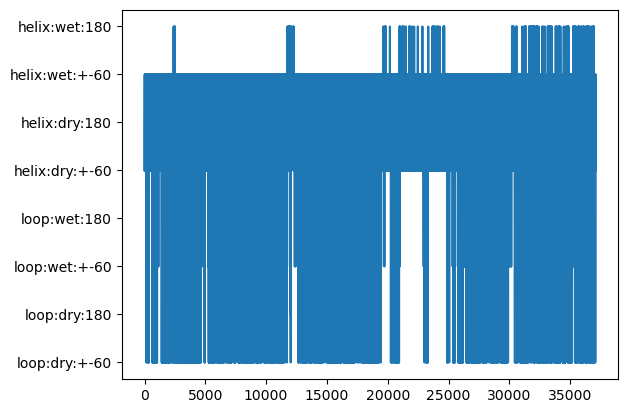

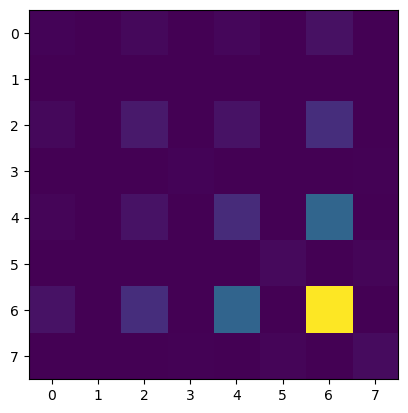

[[ 1806     9  4838    18]
 [   10   355    19   200]
 [ 4790    12 14820    52]
 [   18   208    43   460]]
-------------------------------------------------------------------


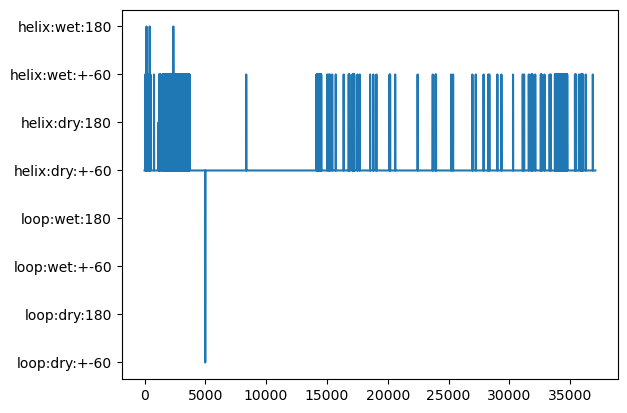

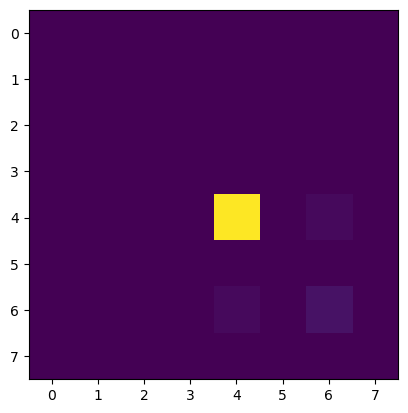

[[33787     2   826     1]
 [    2     1     1     3]
 [  826     1  1625     0]
 [    1     3     0     2]]
-------------------------------------------------------------------


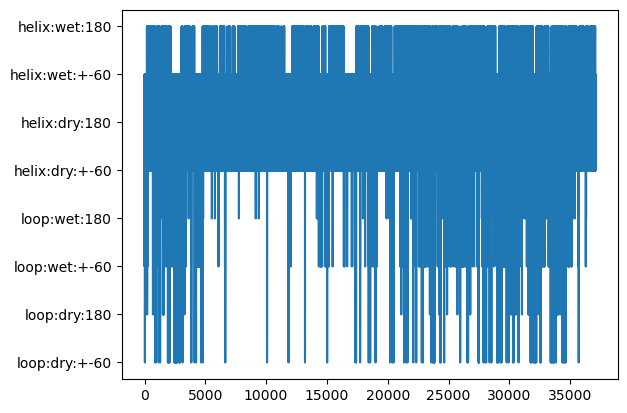

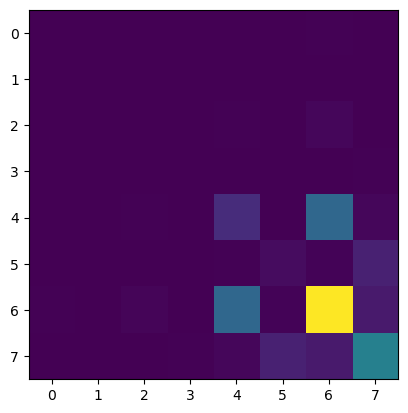

[[ 1746    45  4508   253]
 [   60   453   145  1226]
 [ 4527   157 13577   961]
 [  230  1220   972  5913]]
-------------------------------------------------------------------


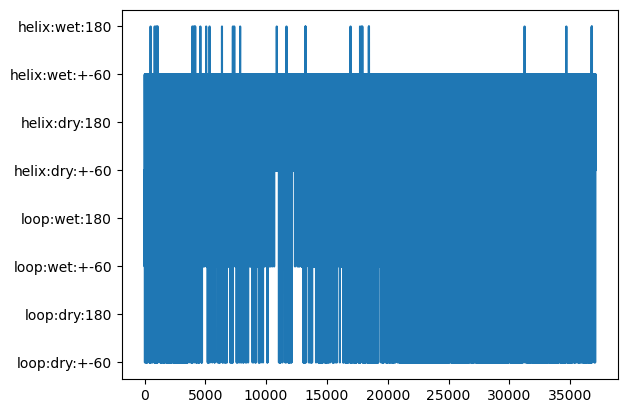

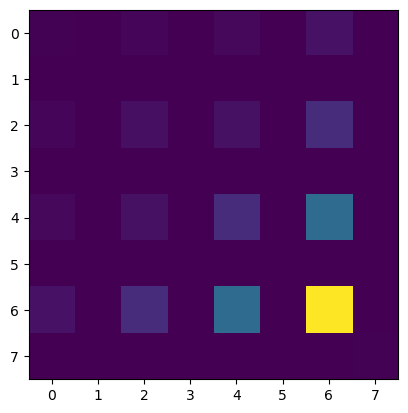

[[ 1974     0  5375     6]
 [    0     0     3     6]
 [ 5387     3 15422    21]
 [    4     7    23    68]]
-------------------------------------------------------------------


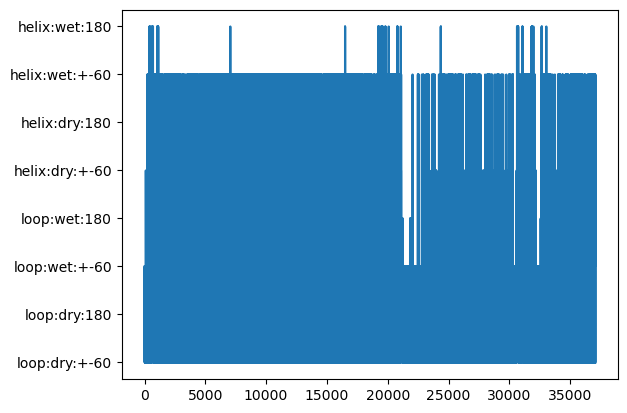

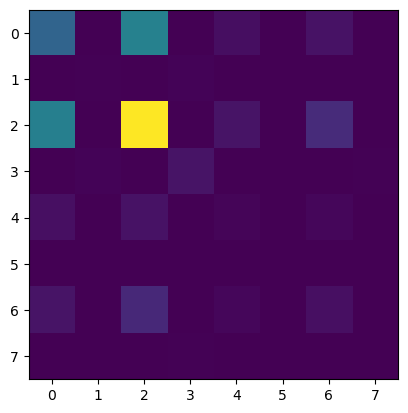

[[185   1 211   0]
 [  0   2   0   5]
 [229   0 506   0]
 [  0   4   1  17]]
-------------------------------------------------------------------


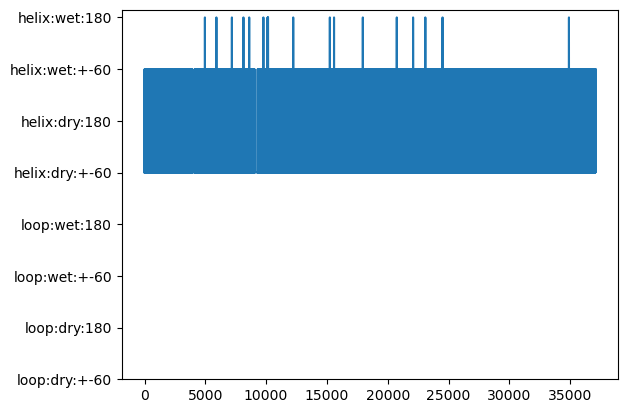

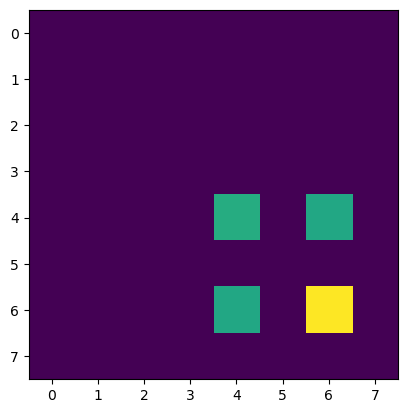

[[ 8121     7  7875     5]
 [    9     2     9     3]
 [ 7876    12 13123    11]
 [    3     2    14    11]]
-------------------------------------------------------------------


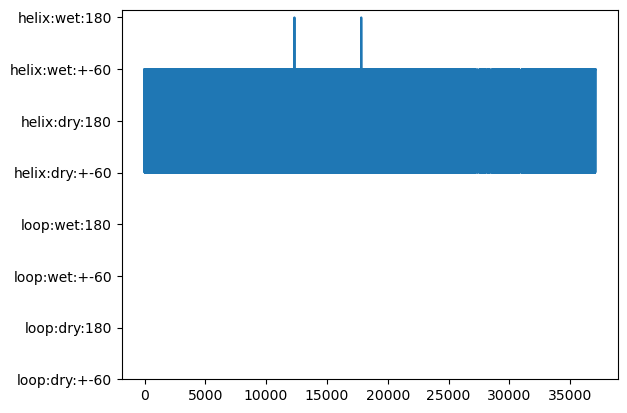

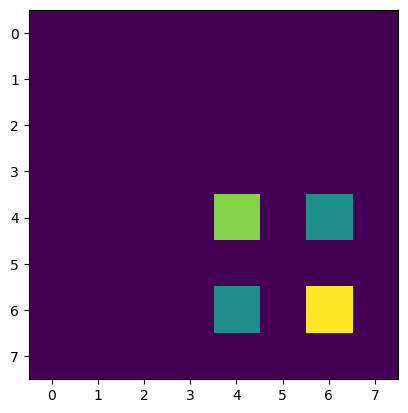

[[10764     0  6563     2]
 [    0     0     1     0]
 [ 6565     1 13185     0]
 [    0     0     2     0]]
-------------------------------------------------------------------


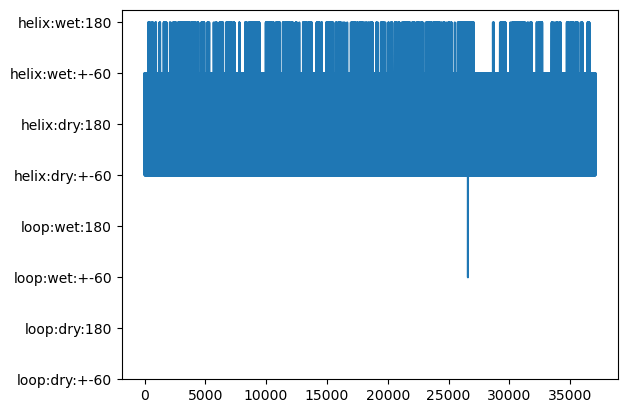

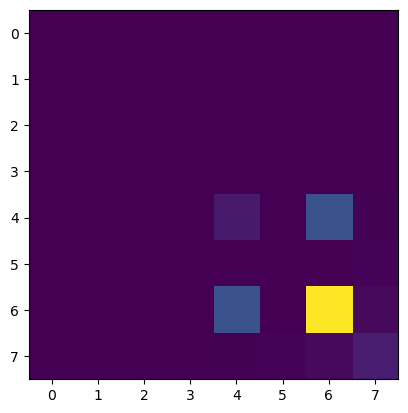

[[ 1555     8  5364   130]
 [   10    61    46   206]
 [ 5361    39 21148   548]
 [  131   215   539  1720]]
-------------------------------------------------------------------


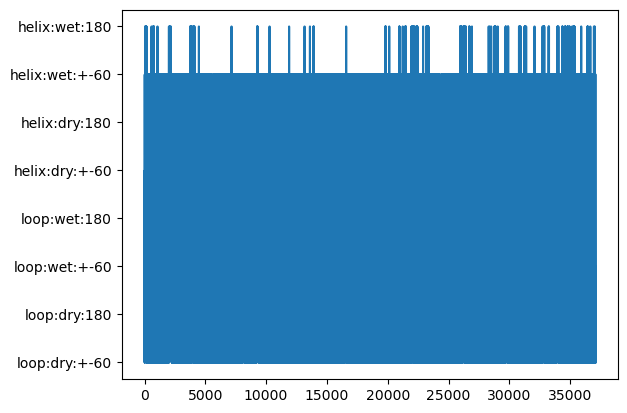

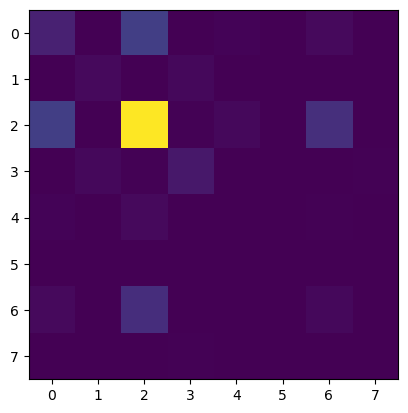

[[ 28   0  76   0]
 [  0   4   0   5]
 [ 62   1 418   3]
 [  0   8   3  18]]
-------------------------------------------------------------------


SystemExit: 0

/home/jonathan/anaconda3/envs/serpents/lib/python3.11/site-packages/IPython/core/interactiveshell.py:3585: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


In [8]:

def load_for_msm(analysis_method):

    #this path actually also contains serine rotamers
    inputpath = "/home/jonathan/Documents/grabelab/rutter-lab-collaboration/thr_rotamers_solvation/resi_data"

    servers = ["wynton", "degrabo"]
    proteins = ["ucp1", "aac1"]

    resn = "thr"

    #loop over servers, proteins, and parallel runs
    for protein in proteins:

        print("---------------------------------------------:" +protein)
        # weights_all = []
        # dg_all = []

        for server in servers:    
            for run in range(1,5):
                #not all servers have the same number of parallel simulations
                if run > 2 and server == "degrabo": continue

                if run > 2:
                    framerate = 2
                else:
                    framerate = 1

                rotamer_data = []
                hbond_data = []
                helix_data = []

                for seg in range(1,20):
                    #load data if it exists
                    rotamer_file = f"{inputpath}/{server}/{protein}/run0{run}/{protein}-{server}-run0{run}-seg{str(seg).zfill(2)}-{resn}-rotamers.npy"
                    hbond_file = f"{inputpath}/{server}/{protein}/run0{run}/{protein}-{server}-run0{run}-seg{str(seg).zfill(2)}-{resn}-hbonds.npy"
                    secstr_file = f"{inputpath}/{server}/{protein}/run0{run}/{protein}-{server}-run0{run}-seg{str(seg).zfill(2)}-{resn}-secstr.npy"

                    if os.path.exists(rotamer_file) and os.path.exists(hbond_file) and os.path.exists(secstr_file):
                        rotamer_data.append(np.load(rotamer_file))
                        hbond_data.append(np.load(hbond_file))
                        helix_data.append(np.load(secstr_file))

                rotamer_data = np.concatenate(rotamer_data, axis = 1)
                hbond_data = np.concatenate(hbond_data, axis = 1)
                helix_data = np.concatenate(helix_data, axis = 1)

                analysis_method(rotamer_data, hbond_data, helix_data)

def msm_processing(rotamer, hbond, helix):

    n_rotamers = 3
    n_hbonds = 3
    n_helices = 2

    state_trj = rotamer + n_rotamers*hbond + n_rotamers*n_hbonds*helix
    state_trj_bin = np.where(rotamer>0,0,1) + 2*np.where(hbond>0,1,0) + 4*helix

    for nr in range(rotamer.shape[0]):

        helix_rotamer_hbonds = np.zeros((2,3,3))

        for x,y,z in zip(helix[nr], rotamer[nr], hbond[nr]):
            helix_rotamer_hbonds[x,y,z]+=1

        r_hb = np.array([[helix_rotamer_hbonds[1,0,0],           np.sum(helix_rotamer_hbonds[1,0,1:3])],
                         [np.sum(helix_rotamer_hbonds[1,1:3,0]), np.sum(helix_rotamer_hbonds[1,1:3,1:3])]])

        if np.all(r_hb>0): 

            resi_trj = state_trj_bin[nr]
            
            plt.plot(resi_trj)
            plt.yticks([0,1,2,3,4,5,6,7], 
                        ["loop:dry:+-60","loop:dry:180","loop:wet:+-60","loop:wet:180",
                         "helix:dry:+-60","helix:dry:180","helix:wet:+-60","helix:wet:180"])
            # plt.ylim(0,17)            
            # plt.yticks([0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17], 
            #                                            ["loop:0hb:180","loop:0hb:-60","loop:0hb:60",
            #                                             "loop:1hb:180","loop:1hb:-60","loop:1hb:60",
            #                                             "loop:2hb:180","loop:2hb:-60","loop:2hb:60",
            #                                             "helix:0hb:180","helix:0hb:-60","helix:0hb:60",
            #                                             "helix:1hb:180","helix:1hb:-60","helix:1hb:60",
            #                                             "helix:2hb:180","helix:2hb:-60","helix:2hb:60"])
            # plt.ylim(0,17)
            plt.show()

            n_states = 8#n_rotamers*n_hbonds*n_helices
            tpm = np.zeros((n_states, n_states), dtype=int)

            for t in range(len(resi_trj)-1):
                tpm[resi_trj[t+1], resi_trj[t]] += 1

            plt.imshow(tpm)
            plt.show()
            print(tpm[4:,4:])
            print("-------------------------------------------------------------------")

    import sys
    sys.exit(0)

load_for_msm(msm_processing)

In [ ]:
####################################################################################
#                                 TRIMMINGS BELOW
####################################################################################
